# 仮説検証: ETTデータのOT予測

EDAで立てた仮説を、時系列順のテストデータで比較します。予測対象は次の観測時刻のOTです（ETThは1時間先、ETTmは15分先）。テスト中は各時点で直近の実測値が利用できるローリング1ステップ予測とします。評価結果は予測上の関連を示すもので、因果関係の証明ではありません。

検証する内容:
- 前日同時刻のOTが、直前のOTだけを使う予測より有用か
- 負荷6変数を加えると、OT履歴だけの予測より改善するか
- Useful負荷とUseless負荷のどちらが追加情報を持つか
- 強相関の負荷変数を片方ずつ除いても性能が保たれるか
- 日内周期・線形トレンドを除いた後も負荷とOTのラグ相関が残るか

## 1. ライブラリとデータ読み込み
ColabのGoogle Driveマウント後に実行します。`DATA_DIR`は既存EDAノートブックと同じマイMac同期先に固定しています。

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("/content/drive/Othercomputers/マイ Mac/assignment-main/data")
DATASET_NAMES = ["ETTh1", "ETTh2", "ETTm1", "ETTm2"]
LOAD_COLUMNS = ["HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL"]
USEFUL_COLUMNS = ["HUFL", "MUFL", "LUFL"]
USELESS_COLUMNS = ["HULL", "MULL", "LULL"]
REQUIRED_COLUMNS = ["date", *LOAD_COLUMNS, "OT"]

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Data directory not found: {DATA_DIR}")


def load_dataset(name):
    path = DATA_DIR / f"{name}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"Dataset file not found: {path}")
    frame = pd.read_csv(path)
    missing = sorted(set(REQUIRED_COLUMNS) - set(frame.columns))
    if missing:
        raise ValueError(f"{name} is missing required columns: {missing}")
    frame = frame[REQUIRED_COLUMNS].copy()
    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")
    frame = frame.dropna(subset=["date"]).sort_values("date").set_index("date")
    frame[LOAD_COLUMNS + ["OT"]] = frame[LOAD_COLUMNS + ["OT"]].apply(
        pd.to_numeric, errors="coerce"
    )
    return frame


datasets = {name: load_dataset(name) for name in DATASET_NAMES}
for name, frame in datasets.items():
    print(f"{name}: {len(frame):,} rows, {frame.index.min()} to {frame.index.max()}")

ETTh1: 17,420 rows, 2016-07-01 00:00:00 to 2018-06-26 19:00:00
ETTh2: 17,420 rows, 2016-07-01 00:00:00 to 2018-06-26 19:00:00
ETTm1: 69,680 rows, 2016-07-01 00:00:00 to 2018-06-26 19:45:00
ETTm2: 69,680 rows, 2016-07-01 00:00:00 to 2018-06-26 19:45:00


In [ ]:
OUTPUT_DIR = Path("/content/drive/Othercomputers/マイ Mac/assignment-main/eda_output")
TABLE_DIR = OUTPUT_DIR / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
print("Results will be saved to:", TABLE_DIR)

Results will be saved to: /content/drive/Othercomputers/マイ Mac/assignment-main/eda_output/tables


## 2. One-step-ahead feature and target construction
`OT_lag_1`は直近OT、`OT_lag_day`は前日の同時刻OTです。テスト区間では各時点で直近の観測が得られるローリング予測を想定します。

In [ ]:
def build_one_step_data(frame, steps_per_day):
    features = pd.DataFrame(index=frame.index)
    features["OT_lag_1"] = frame["OT"]
    features["OT_lag_3"] = frame["OT"].shift(3)
    features["OT_lag_day"] = frame["OT"].shift(steps_per_day - 1)
    features[LOAD_COLUMNS] = frame[LOAD_COLUMNS]

    target = frame["OT"].shift(-1).rename("OT_next")
    valid_rows = features.notna().all(axis=1) & target.notna()
    return features.loc[valid_rows], target.loc[valid_rows]


def regression_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
    }


FEATURE_SETS = {
    "OT history only": ["OT_lag_1", "OT_lag_3", "OT_lag_day"],
    "OT + useful loads": ["OT_lag_1", "OT_lag_3", "OT_lag_day"] + USEFUL_COLUMNS,
    "OT + useless loads": ["OT_lag_1", "OT_lag_3", "OT_lag_day"] + USELESS_COLUMNS,
    "OT + all loads": ["OT_lag_1", "OT_lag_3", "OT_lag_day"] + LOAD_COLUMNS,
}

prediction_results = []
for dataset_name, frame in datasets.items():
    steps_per_day = 24 if dataset_name.startswith("ETTh") else 96
    features, target = build_one_step_data(frame, steps_per_day)
    split_at = int(len(features) * 0.80)
    X_train, X_test = features.iloc[:split_at], features.iloc[split_at:]
    y_train, y_test = target.iloc[:split_at], target.iloc[split_at:]

    baselines = {
        "Persistence baseline": X_test["OT_lag_1"].to_numpy(),
        "Previous-day seasonal baseline": X_test["OT_lag_day"].to_numpy(),
    }
    for model_name, prediction in baselines.items():
        prediction_results.append({
            "dataset": dataset_name,
            "method": model_name,
            **regression_metrics(y_test, prediction),
        })

    for model_name, columns in FEATURE_SETS.items():
        model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
        model.fit(X_train[columns], y_train)
        prediction_results.append({
            "dataset": dataset_name,
            "method": model_name,
            **regression_metrics(y_test, model.predict(X_test[columns])),
        })

prediction_results = pd.DataFrame(prediction_results)
display(prediction_results.round(3))
prediction_results.to_csv(TABLE_DIR / "one_step_prediction_hypothesis_tests.csv", index=False)

,dataset,method,MAE,RMSE
0,ETTh1,Persistence baseline,0.448,0.655
1,ETTh1,Previous-day seasonal baseline,1.714,2.237
2,ETTh1,OT history only,0.446,0.650
3,ETTh1,OT + useful loads,0.436,0.637
4,ETTh1,OT + useless loads,0.450,0.650
5,ETTh1,OT + all loads,0.439,0.639
6,ETTh2,Persistence baseline,0.971,1.331
7,ETTh2,Previous-day seasonal baseline,3.520,4.765
8,ETTh2,OT history only,0.671,0.968
9,ETTh2,OT + useful loads,0.672,0.967


## 3. 負荷特徴の冗長性と調整後ラグ相関
全負荷モデルから負荷列を1つずつ除いてテスト誤差を比較し、各列の追加価値を確認します。さらに、線形トレンドと時間帯別平均を除く前後でETTh1のラグ相関を比較します。

In [ ]:
def remove_linear_trend_and_hourly_pattern(series):
    values = series.to_numpy(dtype=float)
    time_index = np.arange(len(values))
    slope, intercept = np.polyfit(time_index, values, 1)
    detrended = pd.Series(values - (slope * time_index + intercept), index=series.index)
    hourly_effect = detrended.groupby(detrended.index.hour).transform("mean")
    return detrended - hourly_effect


etth1 = datasets["ETTh1"]
max_lag_hours = 168
short_lag_hours = 24
min_abs_correlation = 0.10  # Exploratory reporting threshold, not a significance test.
lags = range(-max_lag_hours, max_lag_hours + 1)
short_lags = range(-short_lag_hours, short_lag_hours + 1)
ot_adjusted = remove_linear_trend_and_hourly_pattern(etth1["OT"])
lag_adjustment_results = []

for load_column in LOAD_COLUMNS:
    raw_correlations = pd.Series({
        lag: etth1[load_column].shift(lag).corr(etth1["OT"])
        for lag in lags
    })
    adjusted_load = remove_linear_trend_and_hourly_pattern(etth1[load_column])
    adjusted_correlations = pd.Series({
        lag: adjusted_load.shift(lag).corr(ot_adjusted)
        for lag in lags
    })

    raw_best_lag = raw_correlations.abs().idxmax()
    adjusted_candidate_lag = adjusted_correlations.abs().idxmax()
    adjusted_candidate_correlation = adjusted_correlations.loc[adjusted_candidate_lag]
    has_clear_adjusted_lag = abs(adjusted_candidate_correlation) >= min_abs_correlation

    raw_short_correlations = raw_correlations.loc[list(short_lags)]
    adjusted_short_correlations = adjusted_correlations.loc[list(short_lags)]
    raw_short_best_lag = raw_short_correlations.abs().idxmax()
    adjusted_short_candidate_lag = adjusted_short_correlations.abs().idxmax()
    adjusted_short_candidate_correlation = adjusted_short_correlations.loc[adjusted_short_candidate_lag]
    has_clear_adjusted_short_lag = abs(adjusted_short_candidate_correlation) >= min_abs_correlation

    lag_adjustment_results.append({
        "load_variable": load_column,
        "raw_best_lag_hours": int(raw_best_lag),
        "raw_correlation": raw_correlations.loc[raw_best_lag],
        "raw_best_lag_within_24h": int(raw_short_best_lag),
        "raw_correlation_within_24h": raw_short_correlations.loc[raw_short_best_lag],
        "adjusted_best_lag_hours": int(adjusted_candidate_lag) if has_clear_adjusted_lag else np.nan,
        "adjusted_candidate_lag_hours": int(adjusted_candidate_lag),
        "adjusted_correlation": adjusted_candidate_correlation,
        "adjusted_lag_status": "Peak below exploratory threshold" if not has_clear_adjusted_lag else "Candidate peak",
        "adjusted_best_lag_within_24h": int(adjusted_short_candidate_lag) if has_clear_adjusted_short_lag else np.nan,
        "adjusted_candidate_lag_within_24h": int(adjusted_short_candidate_lag),
        "adjusted_correlation_within_24h": adjusted_short_candidate_correlation,
        "adjusted_24h_lag_status": "Peak below exploratory threshold" if not has_clear_adjusted_short_lag else "Candidate peak",
    })

lag_adjustment_results = pd.DataFrame(lag_adjustment_results).set_index("load_variable")
display(lag_adjustment_results.round(3))
lag_adjustment_results.to_csv(TABLE_DIR / "etth1_adjusted_lag_correlations.csv")

,raw_best_lag_hours,raw_correlation,raw_best_lag_within_24h,raw_correlation_within_24h,adjusted_best_lag_hours,adjusted_candidate_lag_hours,adjusted_correlation,adjusted_lag_status,adjusted_best_lag_within_24h,adjusted_candidate_lag_within_24h,adjusted_correlation_within_24h,adjusted_24h_lag_status
load_variable,,,,,,,,,,,,
HUFL,-129,0.173,-9,0.161,NaN,-164,0.051,Peak below exploratory threshold,NaN,-24,0.024,Peak below exploratory threshold
HULL,10,0.263,10,0.263,5.0,5,0.372,Candidate peak,5.0,5,0.372,Candidate peak
MUFL,-129,0.175,-9,0.155,NaN,4,-0.076,Peak below exploratory threshold,NaN,4,-0.076,Peak below exploratory threshold
MULL,10,0.254,10,0.254,5.0,5,0.327,Candidate peak,5.0,5,0.327,Candidate peak
LUFL,7,0.133,7,0.133,4.0,4,0.307,Candidate peak,4.0,4,0.307,Candidate peak
LULL,6,0.079,6,0.079,5.0,5,0.195,Candidate peak,5.0,5,0.195,Candidate peak


### Lag-correlation curves within ±24 hours
Compare raw and trend/diurnal-adjusted lag correlations over one day. Positive lag means the load leads OT.

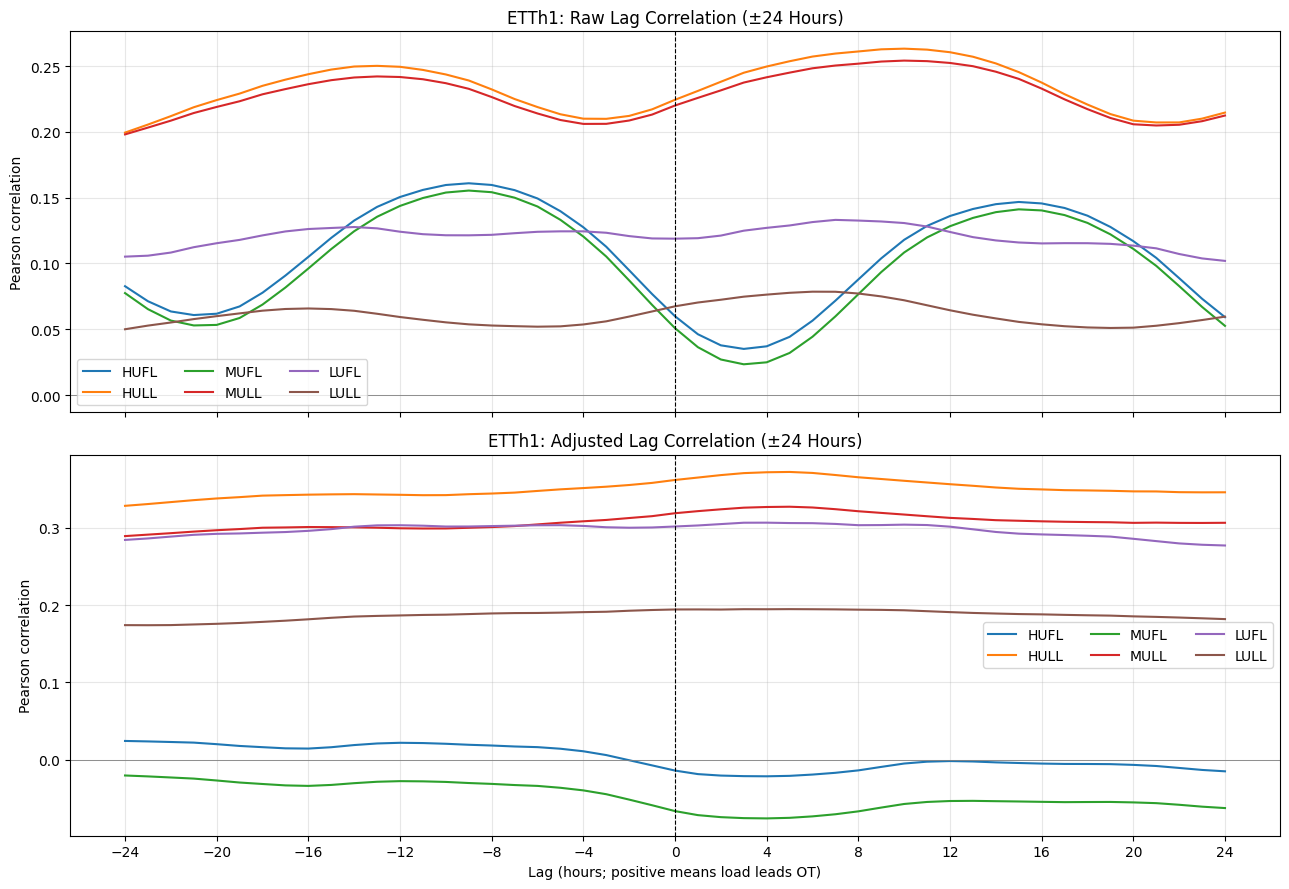

Saved: /content/drive/Othercomputers/マイ Mac/assignment-main/eda_output/figures/etth1_lag_correlations_24h.png


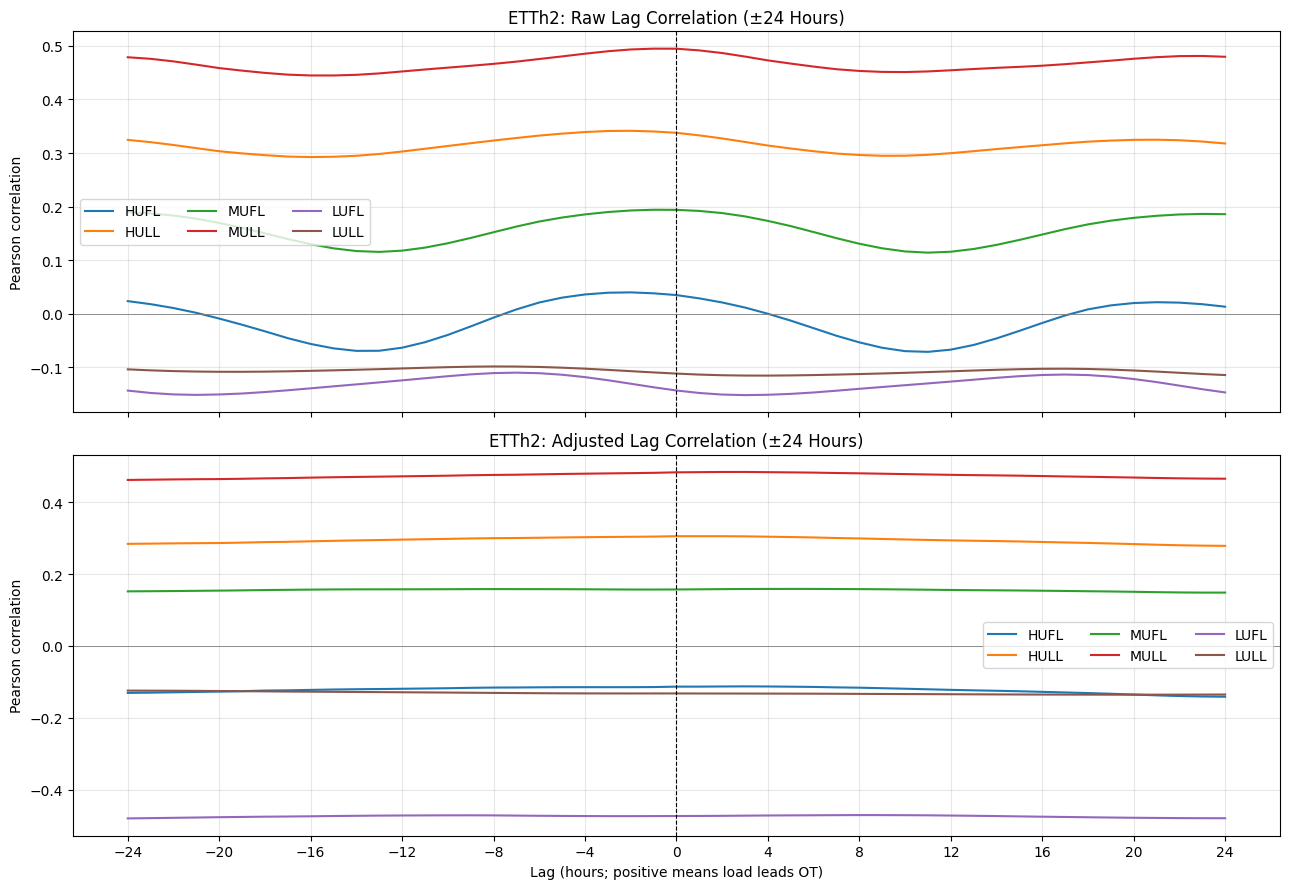

Saved: /content/drive/Othercomputers/マイ Mac/assignment-main/eda_output/figures/etth2_lag_correlations_24h.png


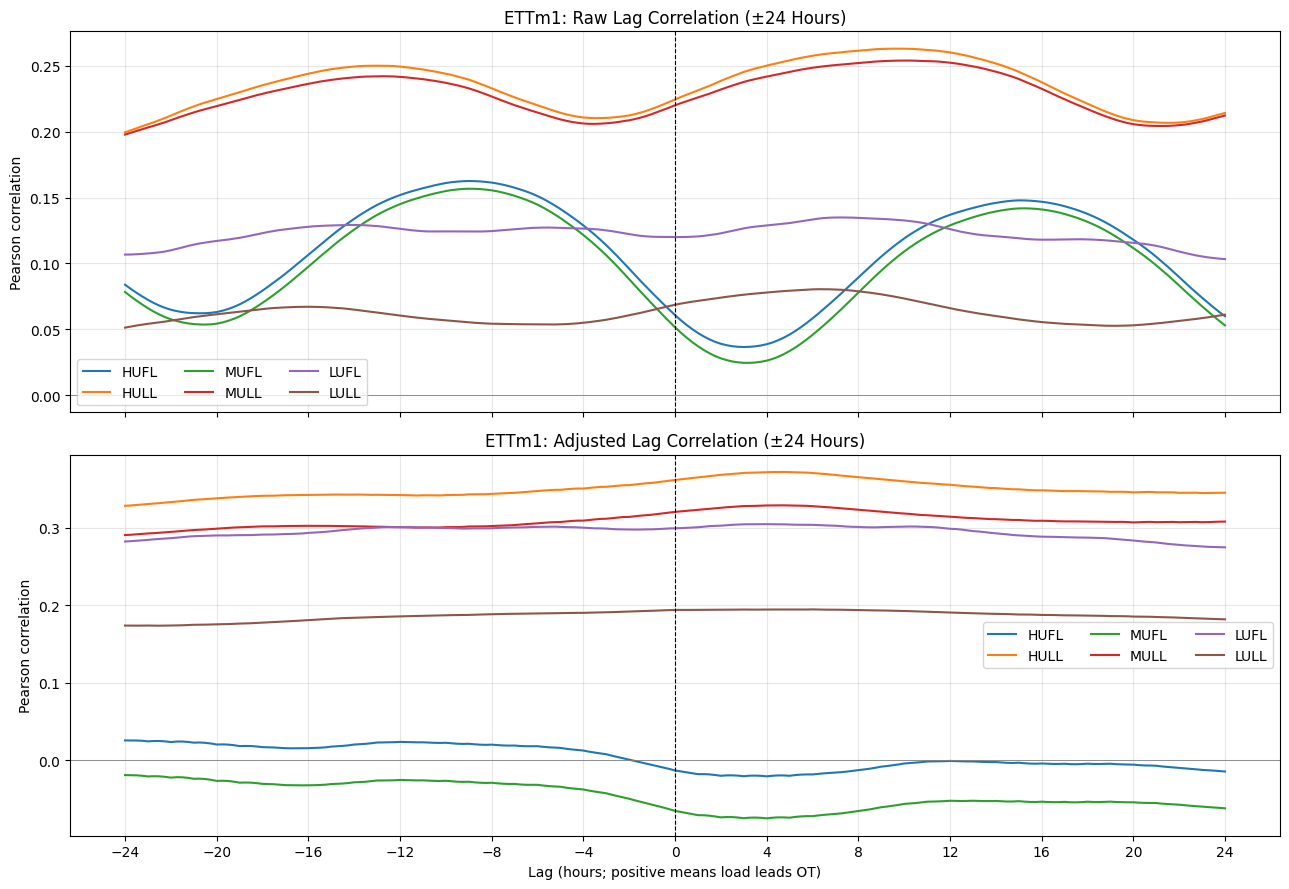

Saved: /content/drive/Othercomputers/マイ Mac/assignment-main/eda_output/figures/ettm1_lag_correlations_24h.png


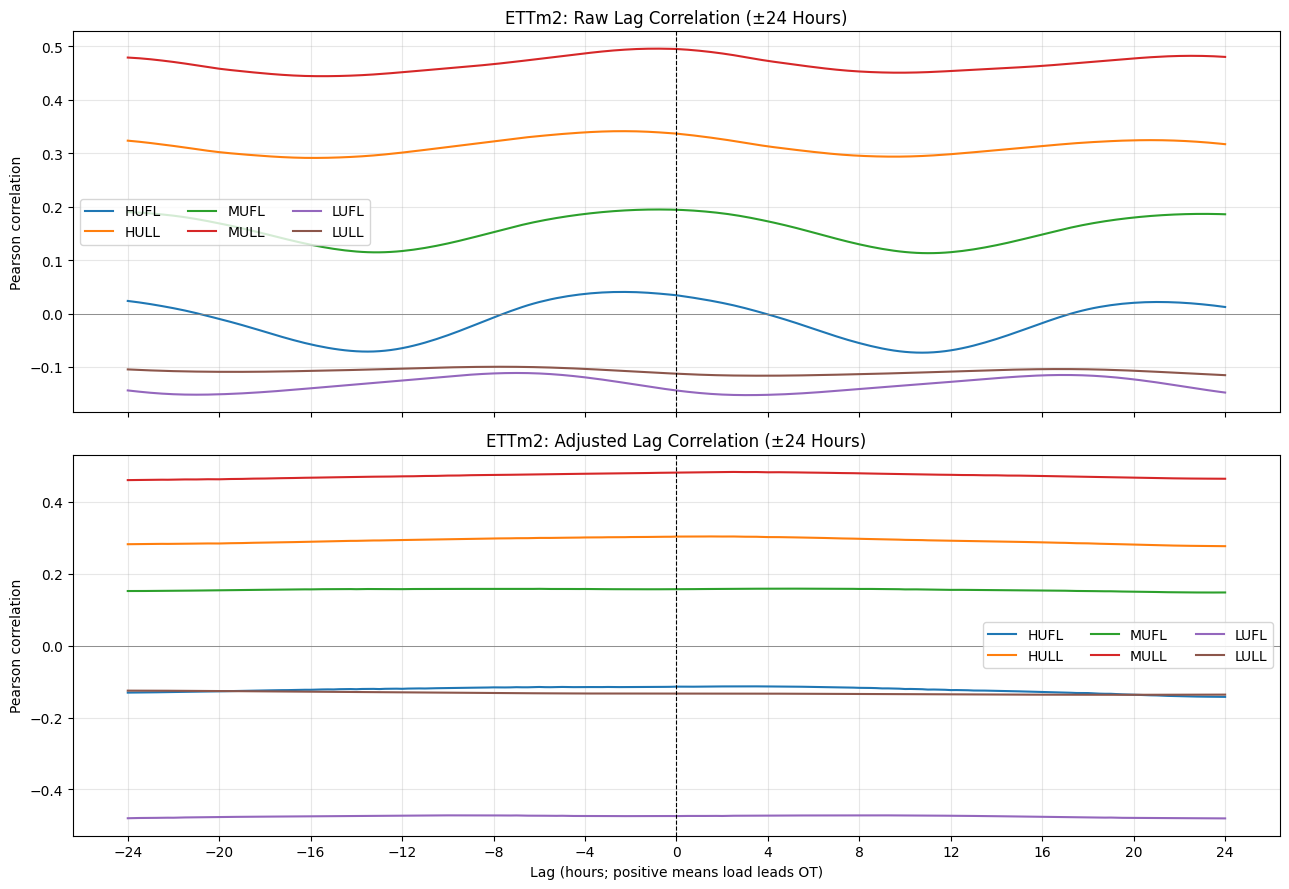

Saved: /content/drive/Othercomputers/マイ Mac/assignment-main/eda_output/figures/ettm2_lag_correlations_24h.png


In [18]:
import matplotlib.pyplot as plt

FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

for dataset_name in DATASET_NAMES:
    frame = datasets[dataset_name]
    samples_per_hour = 1 if dataset_name.startswith("ETTh") else 4
    max_lag_samples = 24 * samples_per_hour
    lag_samples = range(-max_lag_samples, max_lag_samples + 1)
    lag_hours = [lag / samples_per_hour for lag in lag_samples]

    adjusted_ot = remove_linear_trend_and_hourly_pattern(frame["OT"])
    fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

    for load_column in LOAD_COLUMNS:
        raw_curve = [
            frame[load_column].shift(lag).corr(frame["OT"])
            for lag in lag_samples
        ]
        adjusted_load = remove_linear_trend_and_hourly_pattern(frame[load_column])
        adjusted_curve = [
            adjusted_load.shift(lag).corr(adjusted_ot)
            for lag in lag_samples
        ]

        axes[0].plot(lag_hours, raw_curve, label=load_column)
        axes[1].plot(lag_hours, adjusted_curve, label=load_column)

    for ax in axes:
        ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
        ax.axhline(0, color="gray", linewidth=0.6)
        ax.set_ylabel("Pearson correlation")
        ax.set_xticks(range(-24, 25, 4))
        ax.grid(True, alpha=0.3)

    axes[0].set_title(f"{dataset_name}: Raw Lag Correlation (±24 Hours)")
    axes[0].legend(ncol=3)
    axes[1].set_title(f"{dataset_name}: Adjusted Lag Correlation (±24 Hours)")
    axes[1].set_xlabel("Lag (hours; positive means load leads OT)")
    axes[1].legend(ncol=3)
    fig.tight_layout()

    figure_path = FIGURE_DIR / f"{dataset_name.lower()}_lag_correlations_24h.png"
    fig.savefig(figure_path, dpi=160, bbox_inches="tight")
    plt.show()
    print("Saved:", figure_path)

## 4. 高相関負荷ペアの情報重複チェック
`HUFL`–`MUFL`、`HULL`–`MULL`について、全負荷モデル・各片方を除いたモデル・ペア両方を除いたモデルを同じ時系列テスト区間で比較します。除外後にMAE/RMSEがほぼ変わらなければ、残った特徴が似た予測情報を持つ可能性があります。

In [ ]:
CORRELATED_LOAD_PAIRS = {
    "HUFL-MUFL": ("HUFL", "MUFL"),
    "HULL-MULL": ("HULL", "MULL"),
}

pair_ablation_rows = []
for dataset_name, frame in datasets.items():
    steps_per_day = 24 if dataset_name.startswith("ETTh") else 96
    features, target = build_one_step_data(frame, steps_per_day)
    split_at = int(len(features) * 0.80)
    X_train, X_test = features.iloc[:split_at], features.iloc[split_at:]
    y_train, y_test = target.iloc[:split_at], target.iloc[split_at:]
    all_features = FEATURE_SETS["OT + all loads"]

    for pair_name, pair_columns in CORRELATED_LOAD_PAIRS.items():
        comparisons = [("Full load model", ())]
        comparisons.extend((f"Drop {column}", (column,)) for column in pair_columns)
        comparisons.append((f"Drop both ({pair_name})", pair_columns))

        for comparison_name, dropped_columns in comparisons:
            selected_features = [
                column for column in all_features if column not in dropped_columns
            ]
            model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
            model.fit(X_train[selected_features], y_train)
            metrics = regression_metrics(y_test, model.predict(X_test[selected_features]))
            pair_ablation_rows.append({
                "dataset": dataset_name,
                "correlated_pair": pair_name,
                "comparison": comparison_name,
                **metrics,
            })

pair_ablation_results = pd.DataFrame(pair_ablation_rows)
display(pair_ablation_results.round(3))
pair_ablation_results.to_csv(
    TABLE_DIR / "correlated_load_pair_ablation.csv",
    index=False,
)

,dataset,correlated_pair,comparison,MAE,RMSE
0,ETTh1,HUFL-MUFL,Full load model,0.439,0.639
1,ETTh1,HUFL-MUFL,Drop HUFL,0.439,0.638
2,ETTh1,HUFL-MUFL,Drop MUFL,0.438,0.638
3,ETTh1,HUFL-MUFL,Drop both (HUFL-MUFL),0.450,0.650
4,ETTh1,HULL-MULL,Full load model,0.439,0.639
5,ETTh1,HULL-MULL,Drop HULL,0.439,0.639
6,ETTh1,HULL-MULL,Drop MULL,0.439,0.639
7,ETTh1,HULL-MULL,Drop both (HULL-MULL),0.436,0.637
8,ETTh2,HUFL-MUFL,Full load model,0.696,0.972
9,ETTh2,HUFL-MUFL,Drop HUFL,0.689,0.970
